In [403]:
import pandas as pd
import warnings
from statistics import mean
from sklearn.neighbors import KDTree
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [404]:
# PS : Si l'utilisateur n'est pas présent dans les données, le code ne fonctionnera pas

In [405]:
data= pd.read_csv("feedback_aivancity_tinycoaching - feedback_v2.csv").drop(columns=["Age"])
data.head()

,id user,Genre,id formation,Nom formation,id domaine,ref domaine,nom domaine,id compétence,ref compétence,nom compétence,...,nom contenu,type contenu article,type contenu video,type contenu audio,type contenu rich media,durée contenu en s,Contenu déjà proposé,Contenu validé,Date réalisation contenu,Feedback
0,469,Neutre,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,Toujours plus beau,X,NaN,NaN,NaN,180.0,0,1,2020-02-18 09:15:34,Bien
1,1170,Femme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,La France va donner l'Alsace ?!,NaN,X,NaN,NaN,167.0,0,1,2020-05-13 18:44:05,Bien
2,1158,Homme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,La France va donner l'Alsace ?!,NaN,X,NaN,NaN,167.0,0,0,2020-06-27 14:45:04,Bien
3,1176,Femme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,De clic en clic,NaN,NaN,NaN,X,150.0,0,1,2020-05-07 12:54:45,Trop facile
4,1677,Femme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,De clic en clic,NaN,NaN,NaN,X,150.0,0,1,2020-06-22 11:41:19,Trop facile


In [406]:
for column in list(data.columns):
    new_column = column.replace(" ","_")
    data=data.rename(columns={column:new_column})  
data.columns

Index(['id_user', 'Genre', 'id_formation', 'Nom_formation', 'id_domaine',
       'ref_domaine', 'nom_domaine', 'id_compétence', 'ref_compétence',
       'nom_compétence', 'id_theme', 'ref_theme', 'nom_theme', 'id_acquis',
       'ref_acquis', 'nom_acquis', 'Niveau_contenu', 'id_contenu',
       'ref_contenu', 'nom_contenu', 'type_contenu_article',
       'type_contenu_video', 'type_contenu_audio', 'type_contenu_rich_media',
       'durée_contenu_en_s', 'Contenu_déjà_proposé', 'Contenu_validé',
       'Date_réalisation_contenu', 'Feedback'],
      dtype='object')

## Nettoyage

In [407]:
data.Genre= data.Genre.fillna(data.Genre.mode()[0])

In [408]:
list_type_contenu=['type_contenu_article', 'type_contenu_video','type_contenu_audio', 'type_contenu_rich_media']
for column in list_type_contenu:
    data[column]=data[column].fillna(0)
    data[column]=data[column].apply(lambda x: 1 if x=="X" else "Other" if x!="X" and x!=0 else x)

In [409]:
data = data.loc[data.nom_acquis.isna()==False]

In [410]:
data = data.loc[data.durée_contenu_en_s.isna()==False]

In [411]:
data["durée_contenu_en_minutes"]=data.durée_contenu_en_s.apply(lambda x : round(x/60))
data = data.drop(columns=["durée_contenu_en_s"])
data.head()

,id_user,Genre,id_formation,Nom_formation,id_domaine,ref_domaine,nom_domaine,id_compétence,ref_compétence,nom_compétence,...,nom_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,Contenu_déjà_proposé,Contenu_validé,Date_réalisation_contenu,Feedback,durée_contenu_en_minutes
0,469,Neutre,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,Toujours plus beau,1,0,0,0,0,1,2020-02-18 09:15:34,Bien,3
1,1170,Femme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,La France va donner l'Alsace ?!,0,1,0,0,0,1,2020-05-13 18:44:05,Bien,3
2,1158,Homme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,La France va donner l'Alsace ?!,0,1,0,0,0,0,2020-06-27 14:45:04,Bien,3
3,1176,Femme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,De clic en clic,0,0,0,1,0,1,2020-05-07 12:54:45,Trop facile,2
4,1677,Femme,1,DIGITAL,2,DM01,Information et données,5,CP01,1.1 Mener une recherche ou une veille d'inform...,...,De clic en clic,0,0,0,1,0,1,2020-06-22 11:41:19,Trop facile,2


In [412]:
# data.to_csv("clean_data.csv")

In [413]:
data = data.drop(columns=["id_formation","id_domaine","ref_domaine","id_compétence","ref_compétence","id_theme","ref_theme","id_acquis","ref_acquis","id_contenu","ref_contenu","Date_réalisation_contenu"])

In [414]:
def filtrage(data,formation,domaine):
    return data.loc[data["Nom_formation"]==formation].loc[data["nom_domaine"]==domaine].drop(columns=["Nom_formation","nom_domaine"])

In [415]:
filtered_data= filtrage(data,"DIGITAL","Information et données")


# Système de recommandation ( en fonction du feedback et du contenu validé)

In [416]:
# Profile:
# 	• Moyenne de la durée de  vidéos regardées
# 	• % de type de contenus visionnés ( autant de colonnes que de types de contenu)
#   • Moyenne de niveau de contenu
#   • A validé au moins un contenu ou a au moins un feedback positif
# Content Features:
# 	• Nom Contenu
# 	• Niveau Contenu
# 	• Durée Contenu
#   • Type de contenu ( autant de colonnes que de types de contenu)
# Neighbour Profile:
# 	• Moyenne de chaque caractéristique des voisins de notre user

In [417]:
def find(mydict,type):
    myvalue = 0
    for key,value in mydict.items():
        if type == key:
            myvalue = value
    return myvalue

def contenu(data):
    contenu_list=['type_contenu_video','type_contenu_audio','type_contenu_rich_media','type_contenu_article']
    for column in contenu_list:
        if data[column] == 1:
            contenu = column.replace("type_contenu_",'')
            return contenu

In [418]:
def profile(data,user,critere):
    user_data = data.query("id_user=={}".format(user))
    if critere=="Feedback":
        positive_data = user_data.loc[(user_data["Feedback"]=="Bien")|(user_data["Feedback"]=="Trop facile")]
    else:
        positive_data=user_data.query("Contenu_validé==1")
    
    if positive_data.shape[0] != 0:
        x = positive_data.drop(columns=['nom_compétence','nom_theme','nom_acquis','nom_contenu'])
    else:
        x = user_data.drop(columns=['nom_compétence','nom_theme','nom_acquis','nom_contenu'])
        
    x["Type_de_contenu"]= x.apply(lambda x : contenu(x),axis=1)
    x = x.drop(columns=['type_contenu_video','type_contenu_audio','type_contenu_rich_media','type_contenu_article'])
    type_de_contenu = ["article","video","audio","rich_media"]
    pourcentage_type_contenu = dict(round(x["Type_de_contenu"].value_counts()/len(x.Type_de_contenu),2))
    mydict={"id_user": user, 
            "durée_contenu_en_minutes": round(x["durée_contenu_en_minutes"].mean(),2),
            "Niveau_contenu": round(x["Niveau_contenu"].mean(),2)
            }
    for type in type_de_contenu:
        mydict.update({"type_contenu_{}".format(type):find(pourcentage_type_contenu,type)})
    if critere=="Feedback":    
        mydict.update({"A_bons_feedbacks" : bool("Trop facile" in list(user_data.Feedback.unique()) or "Bien" in list(user_data.Feedback.unique()))})
    else : 
        mydict.update({"A_validé_contenus" : bool(1 in list(user_data.Contenu_validé.unique()))})

    return mydict

def neighbour_profile(neighbours_data,critere):
    neighbour_profile = {}
    for column in list(neighbours_data.columns):
        if column not in ["id_user",critere]:
            neighbour_profile.update({column: round(mean( neighbours_data[column]),2)})
    return neighbour_profile

def content_features(data):
    return  data.drop(columns=["id_user","Genre","Feedback","Contenu_validé","Contenu_déjà_proposé","nom_compétence","nom_theme","nom_acquis"]).drop_duplicates()        

In [420]:
def content_based_filtering(user_data,content_data,user_id,critere,num_contents=5):
    """
    Algorithme de recommandation de contenu

    Donne la liste de contenu à recommander à un utilisateur en fonction de ses préférences

    Le modèle compare les préférences de l'utilisateur en terme de contenu aux différents contenus que l'utilisateur
    n'a pas encore consommé et détermine les 5 contenus les plus proches des préférences de l'utilisateur

    Paramètres
    ----------
    user_data : Les données de l'utilisateur (tous les contenus qu'il a consommé)
    content_data : Les contenus présents dans le domaine dans lequel l'utilisateur consomme des contenus
    user_id : L'id de l'utilisateur
    critere : Feedback ou Contenu_Validé , critère par lequel on détermine les préférences de l'utilisateur
    num_contents: Le nombre de contenus à proposer

    """
    tree = KDTree(content_data.drop(columns=["nom_contenu"]))
    user_row = user_data.query("id_user=={}".format(user_id))
    dist,ind = tree.query(user_row.drop(columns=["id_user",critere]),k=num_contents)
    return content_data.iloc[ind.tolist()[0]].nom_contenu.tolist()

def collaborative_filtering(user_data,content_data,user_id,critere,num_similar_users=3,num_contents=5):
    """
    Algorithme de recommandation de contenu

    Donne la liste de contenu à recommander à un utilisateur en fonction de ses préférences

    Le modèle détermine les utilisateurs les plus similaires à notre utilisateur, fait une moyenne de leur préférence pour avoir
    un profil de voisin type puis compare les préférences de ce voisin en terme de contenu aux différents contenus que l'utilisateur
    n'a pas encore consommé et détermine les 5 contenus les plus proches des préférences de l'utilisateur

    Paramètres
    ----------
    user_data : Les données de l'utilisateur (tous les contenus qu'il a consommé)
    content_data : Les contenus présents dans le domaine dans lequel l'utilisateur consomme des contenus
    user_id : L'id de l'utilisateur
    critere : Feedback ou Contenu_Validé , critère par lequel on détermine les préférences de l'utilisateur
    num_similar_users : nombre de voisins semblables à notre utilisateur 
    num_contents: Le nombre de contenus à proposer
    
    """
    tree1 = KDTree(user_data.query("{}==True".format(critere)).drop(columns=["id_user",critere]))
    user_row = user_data.query("id_user=={}".format(user_id))
    dist1,ind1 = tree1.query(user_row.drop(columns=["id_user",critere]),k=num_similar_users)
    original_indices = list(user_data.index)
    filtered_indices = list(user_data.query("{}==True".format(critere)).index)
    mapping = {original_indices[i]:filtered_indices[i]  for i in range(min(len(filtered_indices), len(original_indices)))}
    original_indices = [mapping[i] for i in ind1.tolist()[0]]
    neighbour = pd.DataFrame([neighbour_profile(user_data.iloc[original_indices].query("id_user!={}".format(user_id)),critere=critere)])
    tree2 = KDTree(content_data.drop(columns=["nom_contenu"]))
    dist2,ind2 = tree2.query(neighbour[0:1],k=num_contents)
    return content_data.iloc[ind2.tolist()[0]].nom_contenu.tolist()

def content_recommandation(data,formation,domaine,user_id,critere):
    """
    Détermine l'algorithme de recommandation de contenu à utiliser en fonction de la validation du contenu ou du feedback

    Si notre utilisateur n'a pas de préférences définies (aucun contenu validé ou aucun bon feedback), on utilise le modèle de collaborative filtering
    Dans le cas contraire, on utilise le content based filtering

    
    Paramètres
    ----------
    data : Les données
    formation : La formation que souhaite suivre l'utilisateur
    domaine : le domaine dans lequel l'utilisateur veut consommer des contenus
    user_id : L'id de l'utilisateur
    critere : Feedback ou Contenu_Validé , critère par lequel on détermine les préférences de l'utilisateur

    """
    filtered_data= filtrage(data,formation,domaine)
    contents = content_features(filtered_data)
    contents = contents.loc[~contents["nom_contenu"].isin(list(content_features(filtered_data.query("id_user=={}".format(user_id))["nom_contenu"])))]   
    user_profiles = pd.DataFrame([profile(filtered_data,user,critere) for user in list(filtered_data.id_user.unique())])
    elements = {"Contenu_validé":"A_validé_contenus","Feedback":"A_bons_feedbacks"}
    column = ""
    for key,value in elements.items():
        if key == critere :
            column = value
    X_user = user_profiles[['id_user','Niveau_contenu','type_contenu_article','type_contenu_video','type_contenu_audio','type_contenu_rich_media','durée_contenu_en_minutes',column]]
    if X_user.query("id_user=={}".format(user_id)).to_dict("records")[0][column]==False:
        return collaborative_filtering(user_data = X_user,content_data=contents,user_id=user_id,critere=column)
    else :
        return content_based_filtering(user_data = X_user,content_data=contents,user_id=user_id,critere=column)

In [421]:
formation="SOFT SKILLS"
domaine ="Interpersonnelle"
user_id = 455

content_recommandation(data,formation,domaine,user_id,"Contenu_validé")

['Les messages clés',
 'Préparer, répéter, affiner',
 "Gérer le côté opérationnel d'un discours",
 'Les objectifs du discours',
 'Développez le discours']

In [422]:
content_recommandation(data,formation,domaine,user_id,"Feedback")

['Les messages clés',
 'Préparer, répéter, affiner',
 "Gérer le côté opérationnel d'un discours",
 'Les objectifs du discours',
 'Développez le discours']

## Comment le code fonctionne : (cas ou l'utilisateur n'a pas de préférences définies (pas de bons feedbacks ni de  contenus validés))

### Recommandation en fonction du contenu validé

In [423]:
# On filtre par formation et domaine
filtered_data= filtrage(data,"DIGITAL","Information et données") 
# On crée une matrice des préférences de chaque utilisateur
user_profile = pd.DataFrame([profile(filtered_data,user,"Contenu_validé") for user in list(filtered_data.id_user.unique())])
user_profile.head()

,id_user,durée_contenu_en_minutes,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,A_validé_contenus
0,469,3.00,2.00,1.00,0.00,0,0.00,True
1,1170,2.00,3.67,0.67,0.33,0,0.00,True
2,1158,2.50,4.00,1.00,0.00,0,0.00,True
3,1176,1.50,1.50,0.00,0.00,0,1.00,True
4,1677,2.33,1.67,0.33,0.00,0,0.67,True


In [424]:
X_user = user_profile

In [425]:
# On crée une matrice contenant chaque contenu et ses caractéristiques
contents = content_features(filtered_data)
# On retire les contenus que l'utilisateur a déja consommés
contents = contents.loc[~contents["nom_contenu"].isin(list(content_features(filtered_data.query("id_user=={}".format(user_id))["nom_contenu"])))]   


In [426]:
X_user = X_user[['id_user','Niveau_contenu',
 'type_contenu_article',
 'type_contenu_video',
 'type_contenu_audio',
 'type_contenu_rich_media',
 'durée_contenu_en_minutes',"A_validé_contenus"]]

In [427]:
# On cherche pour un utilisateur donné les utilisateurs qui sont le plus similaires à lui
tree1 = KDTree(X_user.query("A_validé_contenus==True").drop(columns=["id_user","A_validé_contenus"]))
user_id = 60
user_row = X_user.query("id_user=={}".format(user_id))
dist1,ind1 = tree1.query(user_row.drop(columns=["id_user","A_validé_contenus"]),k=3)
original_indices = list(X_user.index)
filtered_indices = list(X_user.query("A_validé_contenus==True").index)
mapping = {original_indices[i]:filtered_indices[i]  for i in range(min(len(filtered_indices), len(original_indices)))}
original_indices = [mapping[i] for i in ind1.tolist()[0]]

In [428]:
user_row

,id_user,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes,A_validé_contenus
36,60,4.0,0.0,1.0,0,0.0,2.0,False


In [429]:
voisins = X_user.iloc[original_indices]
voisins

,id_user,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes,A_validé_contenus
35,475,4.00,0.00,1.00,0,0.0,2.0,True
37,1221,4.00,0.00,1.00,0,0.0,2.0,True
1,1170,3.67,0.67,0.33,0,0.0,2.0,True


In [430]:
# On détermine à partir des 3 plus proches voisins un profil type de voisin
neighbour = pd.DataFrame([neighbour_profile(X_user.iloc[original_indices].query("id_user!={}".format(user_id)),"A_validé_contenus")])
neighbour

,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes
0,3.89,0.22,0.78,0,0.0,2.0


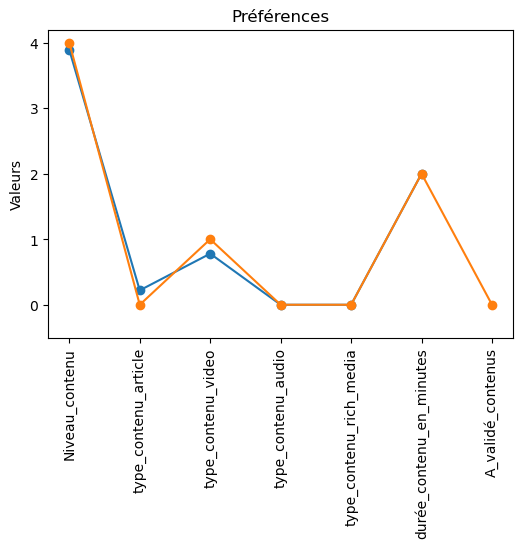

In [431]:
import pandas as pd
import matplotlib.pyplot as plt
 
row_to_plot1 = neighbour.iloc[0]
row_to_plot2 = user_row.iloc[0]

# plot the row
plt.figure(figsize=(6, 4))
plt.plot(row_to_plot1.index, row_to_plot1.values, marker='o',label="Voisin")
id_user = row_to_plot2["id_user"]
row =dict(row_to_plot2)
row.pop("id_user")
row_to_plot2 = pd.Series(row)
plt.plot(row_to_plot2.index, row_to_plot2.values, marker='o',label=f"{id_user}")
plt.ylabel("Valeurs")
plt.title("Préférences")
plt.ylim(-0.5)
plt.xticks(rotation=90)  
plt.show()





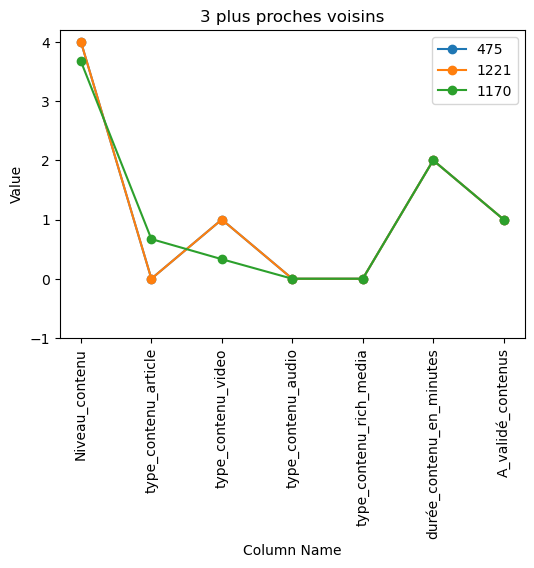

In [432]:
import pandas as pd
import matplotlib.pyplot as plt
 

# select the rows to plot
rows_to_plot = X_user.iloc[original_indices]

# plot the rows
plt.figure(figsize=(6, 4))
for i, row in rows_to_plot.iterrows():
    id_user = row["id_user"]
    row =dict(row)
    row.pop("id_user")
    row = pd.Series(row) 
    plt.plot(row.index, row.values, marker='o', label=f"{id_user}")
plt.xlabel("Column Name")
plt.ylabel("Value")
plt.title("3 plus proches voisins")
plt.ylim(-1)  # set minimum y-axis value to 0
plt.xticks(rotation=90)  # rotate x-axis labels by 45 degrees
plt.legend()  # add legend to the plot
plt.show()


In [433]:
# Pour ce profil type de voisin, on cherche les contenus les plus similaires à ses préférences
from sklearn.neighbors import KDTree
tree2 = KDTree(contents.drop(columns=["nom_contenu"]))
dist2,ind2 = tree2.query(neighbour[0:1],k=5)

In [434]:
# Voici les 5 contenus que l'utilisateur avec l'id 60 pourrait apprécier 
contents.iloc[ind2.tolist()[0]]

,Niveau_contenu,nom_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes
72,4,Pour être en phase avec les enjeux du 21ème si...,0,1,0,0,2
1,4,La France va donner l'Alsace ?!,0,1,0,0,3
65,4,Supprimer sans paniquer,1,0,0,0,2
24,4,Devenez un as de la recherche,0,0,0,1,2
34,4,Créez vous-même vos propres raccourcis,0,0,0,1,2


### Recommandation en fonction du feedback

In [435]:
filtered_data.query("id_user==60")
user_profile = pd.DataFrame([profile(filtered_data,user,"Feedback") for user in list(filtered_data.id_user.unique())])
contents = content_features(filtered_data)
contents = contents.loc[~contents["nom_contenu"].isin(list(content_features(filtered_data.query("id_user=={}".format(user_id))["nom_contenu"])))]   
X_user = user_profile
X_user.head()

,id_user,durée_contenu_en_minutes,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,A_bons_feedbacks
0,469,3.00,2.00,1.00,0.00,0,0.00,True
1,1170,2.00,3.71,0.57,0.29,0,0.14,True
2,1158,2.67,4.00,0.67,0.33,0,0.00,True
3,1176,1.50,1.50,0.00,0.00,0,1.00,True
4,1677,2.33,1.67,0.33,0.00,0,0.67,True


In [436]:
X_user = X_user[['id_user','Niveau_contenu',
 'type_contenu_article',
 'type_contenu_video',
 'type_contenu_audio',
 'type_contenu_rich_media',
 'durée_contenu_en_minutes',"A_bons_feedbacks"]]

In [437]:
from sklearn.neighbors import KDTree
tree = KDTree(X_user.query("A_bons_feedbacks==True").drop(columns=["id_user","A_bons_feedbacks"]))
user_id = 60
user_row = X_user.query("id_user=={}".format(user_id))
dist,ind = tree.query(user_row.drop(columns=["id_user","A_bons_feedbacks"]),k=3)

In [438]:
user_row

,id_user,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes,A_bons_feedbacks
36,60,4.0,0.0,1.0,0,0.0,2.0,False


In [439]:
original_indices = list(X_user.index)
filtered_indices = list(X_user.query("A_bons_feedbacks==True").index)
mapping = {original_indices[i]:filtered_indices[i]  for i in range(min(len(filtered_indices), len(original_indices)))}
original_indices = [mapping[i] for i in ind.tolist()[0]]
X_user.iloc[original_indices].query("id_user!={}".format(user_id))

,id_user,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes,A_bons_feedbacks
38,471,4.0,0.0,1.0,0,0.0,2.0,True
35,475,4.0,0.0,1.0,0,0.0,2.0,True
37,1221,4.0,0.0,1.0,0,0.0,2.0,True


In [440]:
neighbour = pd.DataFrame([neighbour_profile(X_user.iloc[original_indices].query("id_user!={}".format(user_id)),"A_bons_feedbacks")])
neighbour

,Niveau_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes
0,4.0,0.0,1.0,0,0.0,2.0


In [441]:
from sklearn.neighbors import KDTree
tree = KDTree(contents.drop(columns=["nom_contenu"]))
dist,ind = tree.query(neighbour[0:1],k=5)

In [442]:
contents.iloc[ind.tolist()[0]]

,Niveau_contenu,nom_contenu,type_contenu_article,type_contenu_video,type_contenu_audio,type_contenu_rich_media,durée_contenu_en_minutes
1,4,La France va donner l'Alsace ?!,0,1,0,0,3
65,4,Supprimer sans paniquer,1,0,0,0,2
34,4,Créez vous-même vos propres raccourcis,0,0,0,1,2
24,4,Devenez un as de la recherche,0,0,0,1,2
32,4,On ne va pas y aller par quatre chemins,0,0,0,1,2


#### Dans le cas ou l'utilisateur a des préférences définies, on lui propose directement des contenus similaires à ses préférences 